# Previsão de demanda de insumos agrícolas: do SAP à decisão de estoque

**Pergunta de negócio:** quanto de cada insumo cada filial precisa ter em estoque para atender
as próximas 4 semanas (o lead time de reposição) sem empatar capital à toa?

O case percorre o caminho inteiro que um dado faz numa empresa que roda SAP:

1. **Extração SAP** (VBAK, VBAP, KNA1, MARA, MAKT, T023T, T001W), do jeito que ela chega: tudo texto,
   zeros à esquerda, datas `AAAAMMDD`, duplicidades e movimentos que não são demanda;
2. **Camada semântica em SQL**, no estilo das views do SAP Datasphere;
3. **Análise exploratória** e formulação do problema;
4. **Modelo de previsão** avaliado em backtest honesto (sem olhar o futuro);
5. **Decisão**: quanto estoque cada método exige para o mesmo nível de atendimento.

> ⚠️ **Dados 100% sintéticos.** A distribuidora, os clientes e os números são fictícios,
> gerados por `src/demanda/gerar_dados.py` com sazonalidade de safra realista para Mato Grosso.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import pandas as pd
from IPython.display import Image, display

from demanda import avaliacao, camada_sql, features, gerar_dados, graficos, modelos, pipeline
from demanda.config import CALIBRACAO, DADOS_BRUTOS, FIGURAS, NIVEL_SERVICO, SQL_DIR, TESTE

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

if not (DADOS_BRUTOS / "VBAP.csv").exists():
    gerar_dados.salvar(gerar_dados.gerar())

## 1. A extração SAP, como ela chega

Todos os campos são texto. Repare nos zeros à esquerda de `VBELN`, `MATNR` e `KUNNR`, na data
`ERDAT` no formato DATS e no campo `ABGRU` (motivo de recusa) — tudo isso precisa ser tratado
antes de qualquer análise.

In [2]:
vbak = pd.read_csv(DADOS_BRUTOS / "VBAK.csv", dtype=str)
vbap = pd.read_csv(DADOS_BRUTOS / "VBAP.csv", dtype=str, keep_default_na=False)
print(f"VBAK: {len(vbak):,} documentos | VBAP: {len(vbap):,} itens")
display(vbak.head(3), vbap.head(3))

VBAK: 32,632 documentos | VBAP: 75,202 itens


,VBELN,ERDAT,AUART,VKORG,VTWEG,SPART,KUNNR,WAERK
0,0010000001,20200706,ZVEN,1000,10,00,0000100030,BRL
1,0010000002,20200706,ZVEN,1000,10,00,0000100034,BRL
2,0010000003,20200706,ZVEN,1000,10,00,0000100058,BRL


,VBELN,POSNR,MATNR,WERKS,KWMENG,VRKME,NETWR,WAERK,ABGRU,PSTYV
0,0010000001,000010,000000000000100404,1101,15.000,TO,26628.83,BRL,,TAN
1,0010000002,000010,000000000000100301,1101,600.000,DS,2346.02,BRL,,TAN
2,0010000003,000010,000000000000100202,1101,5.000,SC,4424.54,BRL,,TAN


## 2. Camada semântica (SQL no estilo Datasphere)

Os arquivos em `sql/` rodam em ordem no DuckDB: dimensões (`dim_material`, `dim_cliente`,
`dim_centro`), o fato de itens de venda (`fato_vendas`), a `demanda_semanal` densa e a camada de
consumo de BI (`kpi_mensal`, `preco_material`). Abaixo, a view de fato:

In [3]:
print((SQL_DIR / "03_fato_vendas.sql").read_text(encoding="utf-8"))

-- Fato de itens de ordem de venda (VBAK x VBAP): uma linha por item de documento.
--   1. remove a duplicidade da carga delta pela chave do item (VBELN + POSNR);
--   2. converte DATS (AAAAMMDD) em DATE e tira os zeros à esquerda (ALPHA);
--   3. classifica o movimento, que decide o que entra na demanda.
CREATE OR REPLACE VIEW fato_vendas AS
WITH itens AS (
    SELECT
        p.*,
        ROW_NUMBER() OVER (PARTITION BY p.VBELN, p.POSNR ORDER BY p.VBELN) AS ocorrencia
    FROM stg_vbap AS p
)
SELECT
    LTRIM(k.VBELN, '0')                       AS documento,
    CAST(i.POSNR AS INTEGER)                  AS item,
    STRPTIME(k.ERDAT, '%Y%m%d')::DATE         AS data_pedido,
    k.AUART                                   AS tipo_ordem,
    LTRIM(k.KUNNR, '0')                       AS cliente,
    LTRIM(i.MATNR, '0')                       AS material,
    i.WERKS                                   AS centro,
    CAST(i.KWMENG AS DECIMAL(15, 3))          AS quantidade,
    i.VRKME          

In [4]:
con = camada_sql.construir()
camada_sql.relatorio_qualidade(con)

,verificação,quantidade
0,linhas de item na extração (VBAP),75202
1,linhas duplicadas pela carga delta,300
2,itens recusados (ABGRU preenchido),948
3,itens de devolução (ZDEV),1045
4,itens de bonificação (ZBON),2964
5,descrições em outros idiomas (MAKT),30
6,materiais marcados para eliminação (MARA-LVORM),1


Cada linha acima é uma regra de negócio que, se ignorada, distorce a demanda: linhas duplicadas
pela carga delta inflariam o volume, itens recusados e devoluções não são demanda nova, e a
`MAKT` tem uma descrição por idioma (sem o filtro `SPRAS = 'P'` cada material apareceria duas vezes).

In [5]:
demanda, dim_material, preco = pipeline.carregar(con)
display(dim_material.head(4))
demanda.head()

,material,descricao,grupo_mercadoria,familia,unidade,criado_em,marcado_eliminacao
0,100101,SEMENTE SOJA CULTIVAR SJ-01 40KG,SEMSOJA,SEMENTES DE SOJA,SC,2019-03-01,False
1,100102,SEMENTE SOJA CULTIVAR SJ-02 40KG,SEMSOJA,SEMENTES DE SOJA,SC,2019-03-01,False
2,100103,SEMENTE SOJA CULTIVAR SJ-03 40KG,SEMSOJA,SEMENTES DE SOJA,SC,2019-03-01,True
3,100104,SEMENTE SOJA CULTIVAR SJ-04 40KG,SEMSOJA,SEMENTES DE SOJA,SC,2019-03-01,False


,semana,material,centro,quantidade
0,2020-07-06,100101,1101,0.000
1,2020-07-13,100101,1101,0.000
2,2020-07-20,100101,1101,149.000
3,2020-07-27,100101,1101,162.000
4,2020-08-03,100101,1101,188.000


## 3. Entendendo a demanda

Valor vendido por família e safra, direto da camada de consumo de BI:

In [6]:
kpi = camada_sql.tabela(con, "kpi_mensal")
kpi["safra"] = kpi["mes"].apply(lambda d: f"{d.year % 100 - (d.month < 7):02d}/{d.year % 100 + (d.month >= 7):02d}")
(kpi.pivot_table(index="familia", columns="safra", values="valor_vendido", aggfunc="sum") / 1e6) \
    .round(1).rename_axis(columns="R$ milhões por safra")

R$ milhões por safra,20/21,21/22,22/23,23/24,24/25,25/26
familia,,,,,,
ADJUVANTES,2.500,2.800,2.800,3.500,3.800,4.000
FERTILIZANTES,74.200,90.000,108.000,74.700,94.600,98.500
FUNGICIDAS,19.700,19.700,20.000,19.800,23.400,26.600
HERBICIDAS,8.100,8.600,9.700,10.600,11.900,12.900
INOCULANTES,3.300,3.400,3.500,4.100,4.500,4.600
INSETICIDAS,14.200,17.900,17.200,19.300,19.400,20.900
SEMENTES DE MILHO,52.400,54.300,60.200,61.700,78.900,72.300
SEMENTES DE SOJA,40.900,42.800,42.700,43.600,55.200,62.700


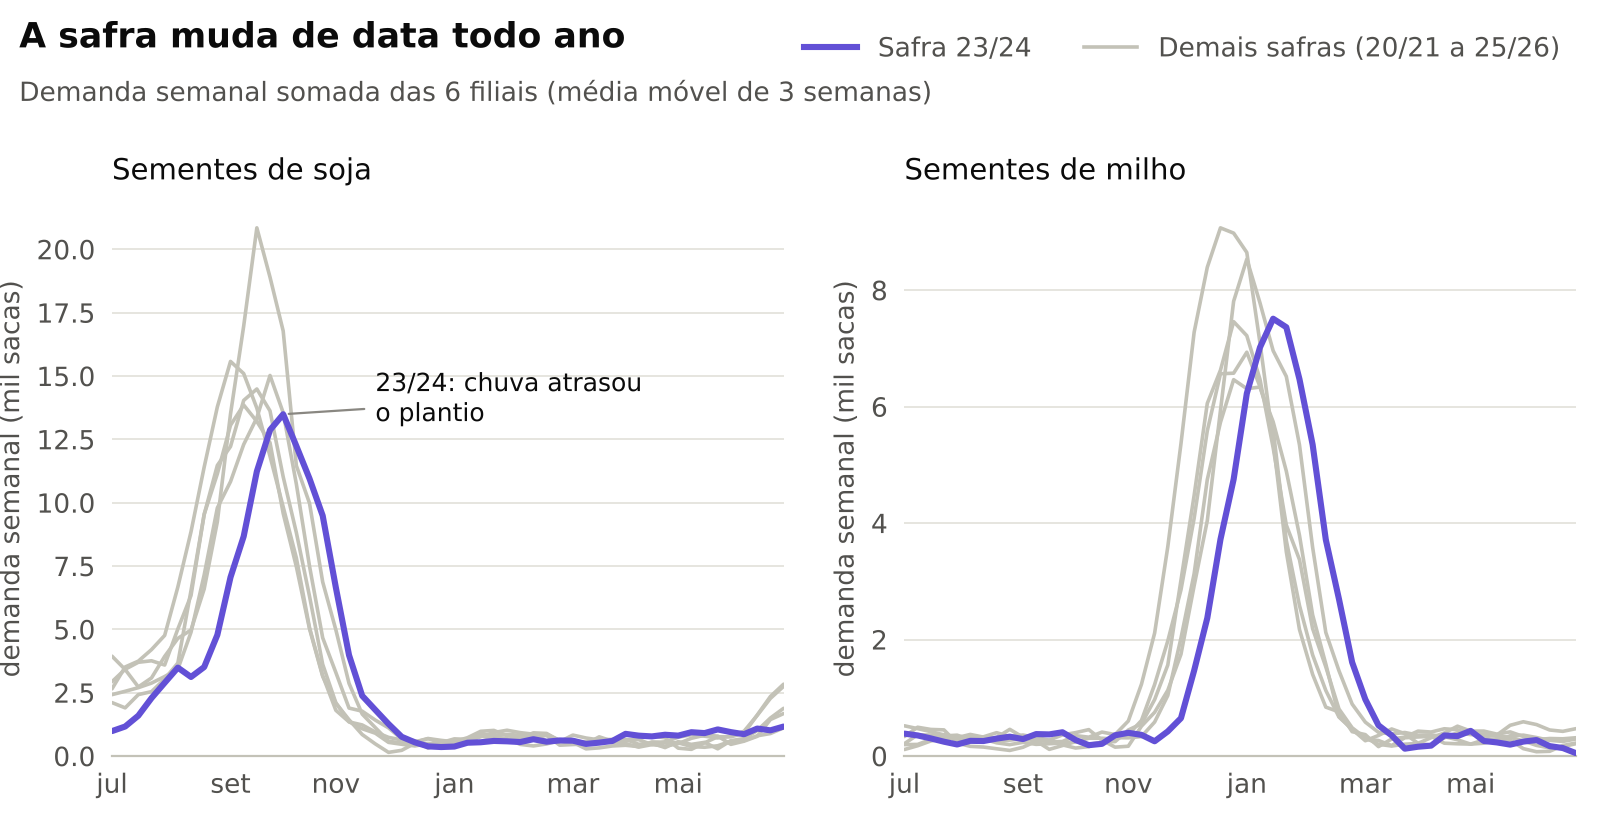

In [7]:
graficos.sazonalidade(demanda, dim_material, FIGURAS / "sazonalidade-claro.png", "claro")
display(Image(filename=str(FIGURAS / "sazonalidade-claro.png"), width=900))

Três características moldam o problema:

* **Sazonalidade forte e diferente por família:** sementes de soja e inoculantes concentram a
  demanda entre agosto e outubro; sementes de milho e ureia, entre dezembro e fevereiro (safrinha).
* **O calendário muda todo ano:** na safra 23/24 as chuvas atrasaram e o pico veio semanas depois.
  Um método que copia o ano anterior erra justamente no pico.
* **Demanda intermitente:** em boa parte das semanas uma filial não vende um item específico.

In [8]:
inter = demanda.merge(dim_material[["material", "familia"]], on="material")
(inter.assign(sem_venda=inter["quantidade"].eq(0))
      .groupby("familia")["sem_venda"].mean().sort_values().rename("% de semanas sem venda")
      .map("{:.0%}".format).to_frame())

,% de semanas sem venda
familia,
INOCULANTES,28%
ADJUVANTES,43%
INSETICIDAS,46%
FUNGICIDAS,47%
FERTILIZANTES,57%
HERBICIDAS,59%
SEMENTES DE MILHO,62%
SEMENTES DE SOJA,65%


## 4. Formulação

* **Unidade de previsão:** material × filial (180 séries).
* **Alvo:** demanda acumulada das **4 semanas seguintes** a cada semana de origem — é o que o
  estoque precisa cobrir enquanto a reposição não chega.
* **Features** (só com o que se sabia até a semana de origem): nível recente da série, o mesmo
  período do ano anterior (inclusive deslocado em ±2 semanas), a razão entre as últimas semanas e o
  ano anterior na série, na família da filial e na família inteira (é ela que denuncia um plantio
  adiantado ou atrasado), semana da safra, família, filial e material.
* **Modelo global** de gradient boosting (`HistGradientBoostingRegressor`) com perda Poisson para a
  previsão central e perda quantílica (P90) para medir a incerteza. As séries são normalizadas pela
  própria escala e o treino é ponderado por valor (R$).
* **Baselines:** média móvel das últimas 4 semanas e sazonal ingênuo (o mesmo período do ano anterior).

**Backtest:** o modelo é retreinado a cada 13 semanas usando apenas janelas cujo alvo já era
conhecido. A safra 24/25 serve de calibração e a 25/26 é o teste. Há um teste automatizado
(`tests/test_features.py`) que altera o futuro e confirma que nenhuma feature muda.

In [9]:
base = features.montar_base(demanda, dim_material)
print(f"{len(base):,} linhas (série × semana de origem), {len(features.FEATURES)} features")
base[["material", "centro", "semana_origem", "soma_4", "aa_prox_4", "ft_razao_aa", "y"]].dropna().sample(5, random_state=1)

46,260 linhas (série × semana de origem), 23 features


,material,centro,semana_origem,soma_4,aa_prox_4,ft_razao_aa,y
5318,100104,1103,2024-12-23,1.927,1.413,1.172,0.000
34166,100601,1101,2026-03-16,2.076,12.555,0.775,970.000
24050,100405,1104,2024-06-03,3.686,0.000,1.176,42.000
26629,100501,1102,2024-08-05,1.703,1.946,2.139,"4,360.000"
36807,100602,1106,2022-08-22,0.408,0.000,1.355,190.000


In [10]:
%%time
prev = modelos.backtest(base, preco, inicio=CALIBRACAO[0], fim=TESTE[1])
prev["preco"] = prev["material"].map(preco).astype(float)
prev = prev[(prev["soma_52"] > 0) | (prev["y"] > 0)]          # séries ativas
calibracao = prev[prev["origem"].between(*CALIBRACAO)]
teste = prev[prev["origem"].between(*TESTE)]

CPU times: user 1min 37s, sys: 6.42 s, total: 1min 44s
Wall time: 1min 12s


## 5. Resultado da previsão

Métrica: **WAPE em valor** — soma dos erros absolutos em R$ dividida pela demanda em R$
(sacas, toneladas e litros não se somam; reais sim). Viés positivo = superestimou.

In [11]:
pd.concat({"calibração (safra 24/25)": avaliacao.tabela_metricas(calibracao),
           "teste (safra 25/26)": avaliacao.tabela_metricas(teste)}).droplevel(1) \
    .style.format("{:.1%}")

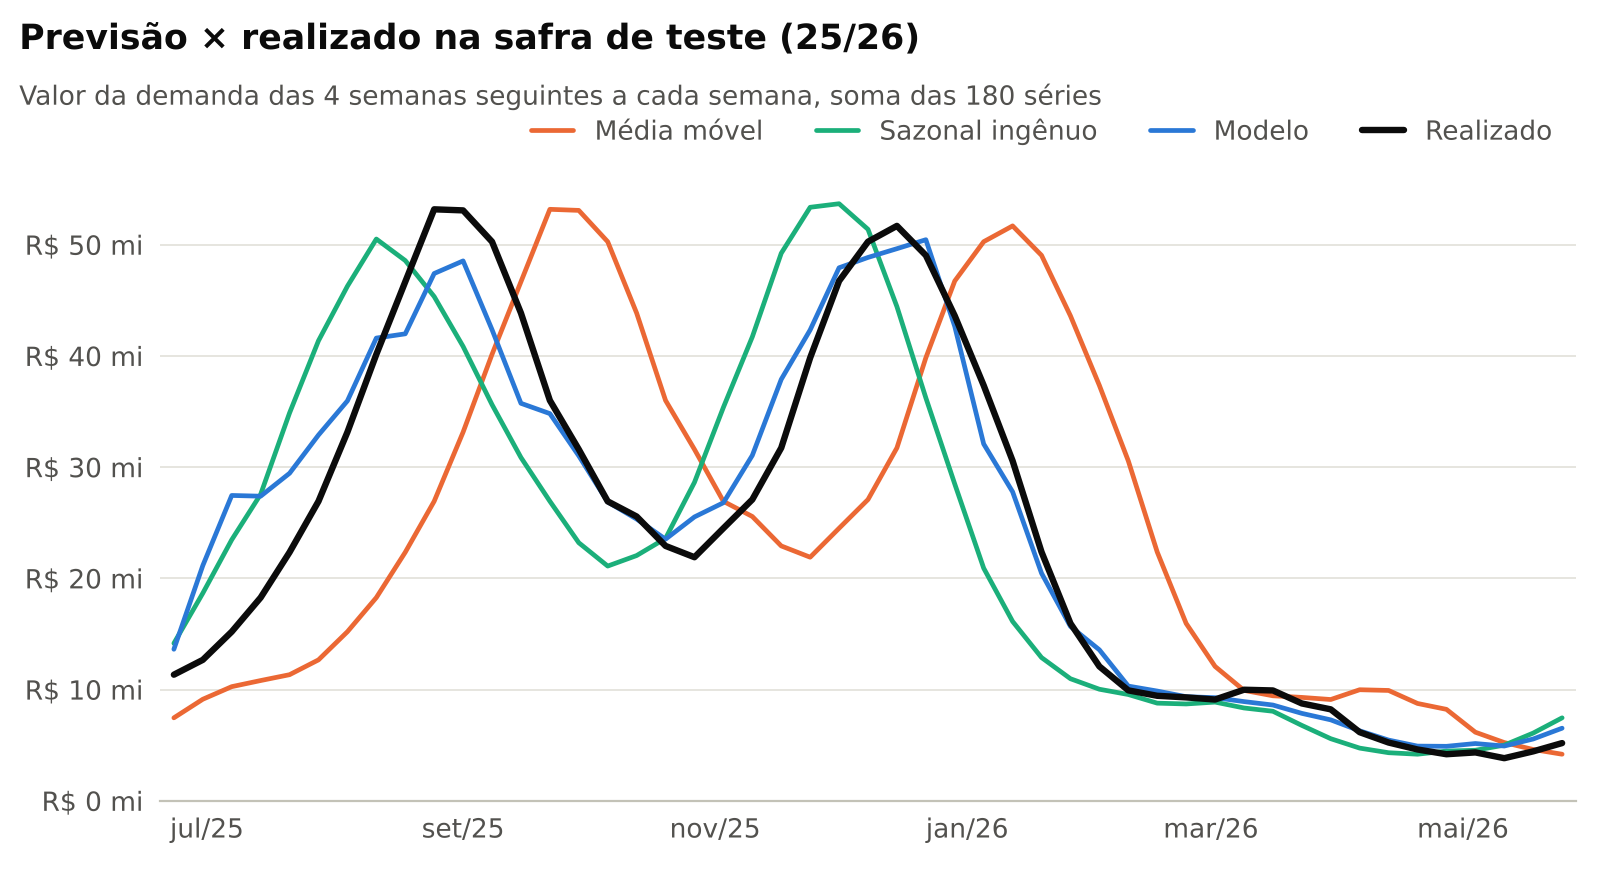

In [12]:
graficos.previsao_vs_real(teste, FIGURAS / "previsao-vs-real-claro.png", "claro")
display(Image(filename=str(FIGURAS / "previsao-vs-real-claro.png"), width=900))

A média móvel chega sempre atrasada: quando ela "percebe" o pico, ele já passou. O sazonal
ingênuo acerta o formato, mas carrega a data do ano anterior. O modelo combina os dois sinais e
ainda lê a razão contra o ano anterior para ajustar o calendário.

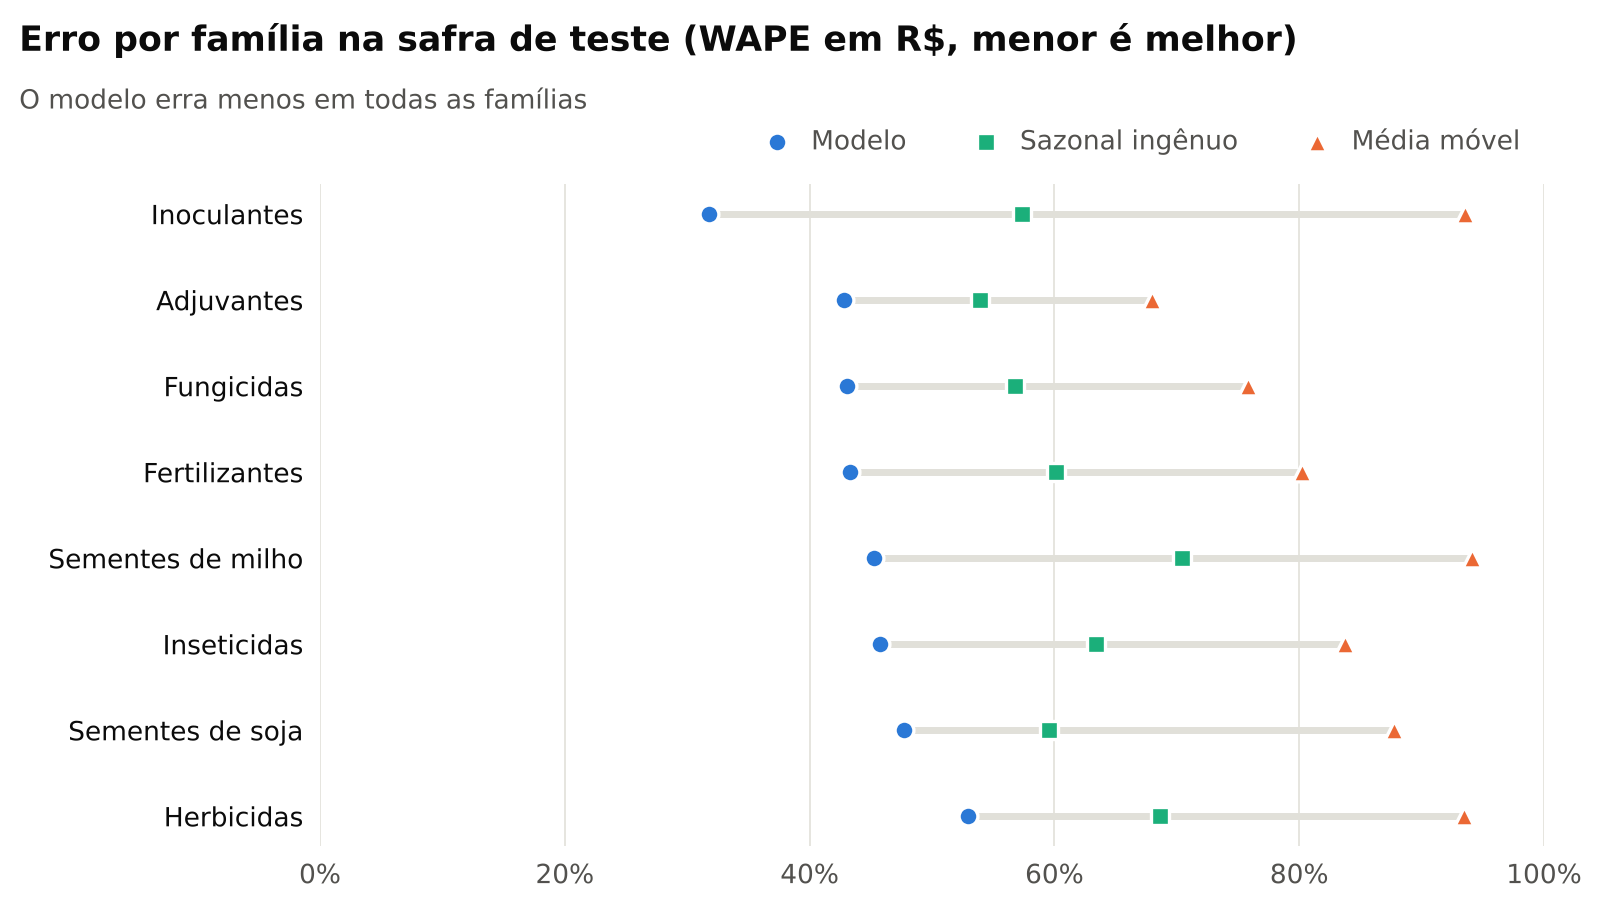

In [13]:
por_familia = avaliacao.tabela_metricas(teste, por="familia")
graficos.erro_por_familia(por_familia, FIGURAS / "erro-por-familia-claro.png", "claro")
display(Image(filename=str(FIGURAS / "erro-por-familia-claro.png"), width=900))

## 6. Da previsão à decisão de estoque

A mesma regra vale para todos os métodos: **estoque-alvo = previsão + z × incerteza**.

* Nos baselines a incerteza é o desvio-padrão histórico do erro de cada série (o estoque de
  segurança clássico, fixo o ano todo).
* No modelo a incerteza vem do quantil P90 e é **condicional**: cresce no pico da safra e
  encolhe na entressafra.

O indicador de serviço é o **atendimento em valor** (fill rate): fração do R$ demandado que
teria sido atendido na hora. Variando `z`, cada método desenha uma curva de atendimento × estoque.

In [14]:
politica, curvas = avaliacao.avaliar_politicas(calibracao, teste)
politica.style.format({"z calibrado": "{:.2f}", "atendimento no teste": "{:.1%}",
                       "estoque médio (R$ mi)": "{:.1f}",
                       f"estoque p/ {NIVEL_SERVICO:.0%} no teste (R$ mi)": "{:.1f}",
                       "economia do modelo": "{:.0%}"})

,z calibrado,atendimento no teste,estoque médio (R$ mi),estoque p/ 95% no teste (R$ mi),economia do modelo
método,,,,,
Modelo (gradient boosting),4.46,99.2%,79.7,44.1,0%
Média móvel 4 semanas,1.74,93.6%,78.4,85.1,48%
Sazonal ingênuo (ano anterior),2.04,97.2%,78.9,64.3,31%


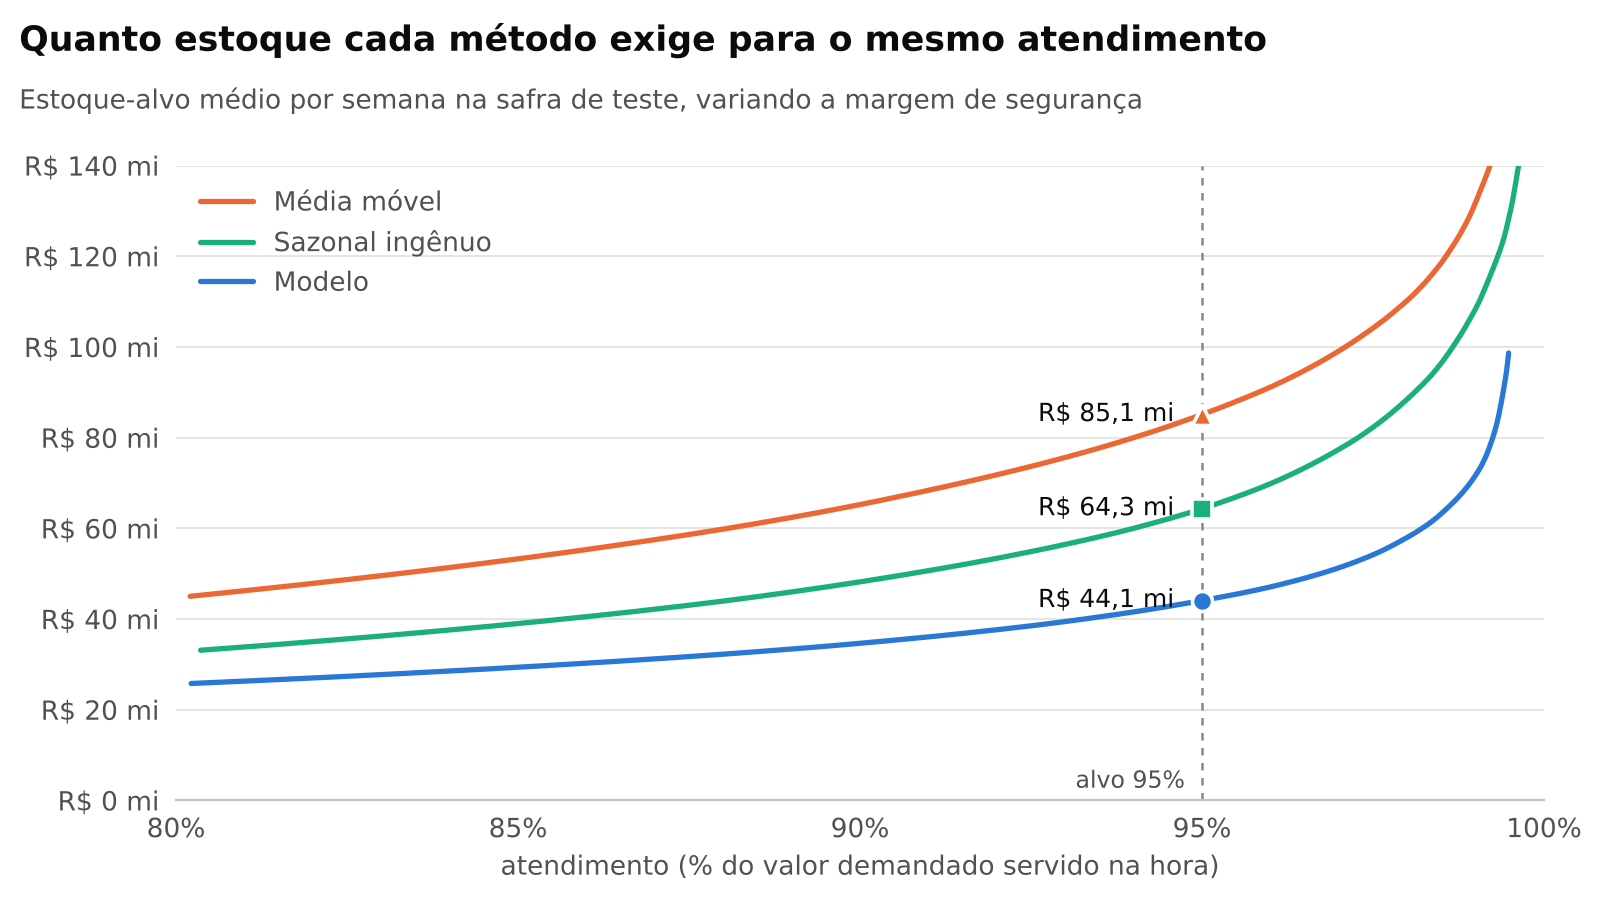

In [15]:
graficos.tradeoff_estoque(curvas, NIVEL_SERVICO, FIGURAS / "tradeoff-estoque-claro.png", "claro")
display(Image(filename=str(FIGURAS / "tradeoff-estoque-claro.png"), width=900))

**Leitura:** para atender 95% do valor demandado na safra de teste, o modelo precisa de bem menos
estoque médio que os baselines — a coluna *economia do modelo* mostra quanto capital de giro deixa
de ficar parado.

**Ponto de atenção honesto:** o `z` calibrado na safra 24/25 não transfere perfeitamente para a
25/26. A 24/25 foi mais volátil (lançamento da cultivar SJ-05, saída da SJ-03 e choque de demanda
no milho), então todas as políticas ficaram mais conservadoras do que o necessário na safra seguinte
— o modelo chegou a quase 99% de atendimento. Em produção, `z` deve ser recalibrado periodicamente
com o erro mais recente; a curva acima é a comparação justa entre os métodos, porque mostra o custo
de cada um em qualquer nível de serviço.

## 7. Recomendação para a próxima janela

Com o modelo treinado em todo o histórico e o `z` recalibrado na safra mais recente, a saída
operacional é uma lista de estoque-alvo por material e filial para as próximas 4 semanas:

In [16]:
z_atual = avaliacao.calibrar_z(teste, "prev_modelo")
recomendacao = pipeline.recomendacao_compra(base, preco, dim_material, z_atual)
print(f"z recalibrado na safra 25/26: {z_atual:.2f}")
recomendacao.head(10)

z recalibrado na safra 25/26: 1.58


,a_partir_de,centro,material,descricao,familia,unidade,previsao_4_semanas,p90,estoque_alvo,valor_estoque_alvo
81,2026-06-29,1104,100403,FERTILIZANTE NPK 02-20-18 BIG BAG,FERTILIZANTES,TO,132.000,318.000,361.000,"805,826.560"
9,2026-06-29,1104,100102,SEMENTE SOJA CULTIVAR SJ-02 40KG,SEMENTES DE SOJA,SC,"1,078.000","2,027.000","2,249.000","714,550.850"
22,2026-06-29,1105,100104,SEMENTE SOJA CULTIVAR SJ-04 40KG,SEMENTES DE SOJA,SC,746.000,"1,913.000","2,184.000","660,846.320"
4,2026-06-29,1105,100101,SEMENTE SOJA CULTIVAR SJ-01 40KG,SEMENTES DE SOJA,SC,983.000,"1,898.000","2,111.000","640,288.360"
75,2026-06-29,1104,100402,FERTILIZANTE KCL 00-00-60 BIG BAG,FERTILIZANTES,TO,131.000,291.000,328.000,"620,733.480"
69,2026-06-29,1104,100401,FERTILIZANTE MAP 11-52-00 BIG BAG,FERTILIZANTES,TO,93.000,218.000,247.000,"606,514.050"
79,2026-06-29,1102,100403,FERTILIZANTE NPK 02-20-18 BIG BAG,FERTILIZANTES,TO,133.000,241.000,266.000,"593,766.940"
82,2026-06-29,1105,100403,FERTILIZANTE NPK 02-20-18 BIG BAG,FERTILIZANTES,TO,108.000,234.000,264.000,"589,302.530"
29,2026-06-29,1106,100105,SEMENTE SOJA CULTIVAR SJ-05 40KG,SEMENTES DE SOJA,SC,737.000,"1,397.000","1,551.000","573,665.790"
3,2026-06-29,1104,100101,SEMENTE SOJA CULTIVAR SJ-01 40KG,SEMENTES DE SOJA,SC,940.000,"1,694.000","1,870.000","567,190.540"


## 8. Conclusões, limitações e próximos passos

**Conclusões**

* A camada semântica resolveu os problemas clássicos da extração SAP antes da modelagem — sem
  ela, duplicidades, devoluções e recusas entrariam como demanda.
* Na safra de teste, o modelo errou bem menos que os dois baselines em todas as famílias.
* O ganho que importa para o negócio é o capital: no mesmo nível de atendimento, a previsão
  melhor com incerteza condicional exige bem menos estoque.

**Limitações**

* Dados sintéticos: o comportamento real tem preço, crédito, clima e campanhas comerciais que
  aqui não existem.
* Lead time fixo de 4 semanas para todos os itens; na vida real ele varia por fornecedor.
* Itens novos sem histórico dependem dos sinais da família até acumularem vendas.

**Como isso iria para produção**

1. As views de `sql/` viram views no SAP Datasphere sobre as tabelas replicadas do S/4HANA ou ECC
   (equivalências de dialeto no README).
2. O pipeline Python roda em contêiner, agendado semanalmente, lendo a view `demanda_semanal`.
3. As previsões e o estoque-alvo voltam para uma tabela local no Datasphere e alimentam um painel
   no Power BI, com monitoramento mensal do WAPE por família.